# Creditworthiness modelling: XGB Classification

In [365]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import optuna
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, recall_score, accuracy_score, precision_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay, 
                            precision_recall_curve, PrecisionRecallDisplay)

## <font color="orange"> Data loading <font>

In [366]:
# load data
path = "../data/processed-data/processed_data.csv"
df = pd.read_csv(path)

In [367]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32574 entries, 0 to 32573
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   person_age_years                  32574 non-null  int64  
 1   person_home_ownership             32574 non-null  str    
 2   person_emp_length_years           31679 non-null  float64
 3   loan_intent                       32574 non-null  str    
 4   loan_grade                        32574 non-null  str    
 5   loan_int_rate                     29459 non-null  float64
 6   loan_status                       32574 non-null  int64  
 7   cb_person_default_on_file         32574 non-null  int64  
 8   cb_person_cred_hist_length_years  32574 non-null  int64  
 9   loan_term_months                  32574 non-null  int64  
 10  loan_to_income_ratio              32574 non-null  float64
 11  open_accounts                     32574 non-null  int64  
 12  credit_utilizat


## <font color="orange"> Preparation <font>

In [368]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [369]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
#X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.2, stratify=y_tv, random_state=42)

## <font color="orange"> XGB Classifier <font>

In [370]:
# feature division 
binary_features = ["high_lti", "loan_grade_sep", "high_income", "high_lti_x_rent", "cb_person_default_on_file"]
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
numeric_features = [ft for ft in numeric_features if ft not in binary_features]
ohe_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

In [371]:
# cv 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# processor pipeline
preprocessor = ColumnTransformer(
        transformers=[
            ("ohe", Pipeline([
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]), ohe_features),
        ],
        remainder="passthrough",
)

# best Fbeta score
BETA = 1.0   # 1.0 for F1, 2.0 for F2
def best_fbeta(y_true, p, beta=BETA):
    prec, rec, thr = precision_recall_curve(y_true, p)
    b2 = beta ** 2
    f = (1 + b2) * prec * rec / (b2 * prec + rec + 1e-12)
    i = np.argmax(f[:-1])          # last point has no threshold
    return f[i], thr[i]

In [372]:
#ib_ratio = (y_train==0).sum() / (y_train==1).sum()
y_arr = np.asarray(y_train)
# fit the preprocessor once per fold
folds = []
for trn, val in cv.split(X_train, y_arr):
    pre = clone(preprocessor).fit(X_train.iloc[trn])
    folds.append((
        pre.transform(X_train.iloc[trn]), y_arr[trn],
        pre.transform(X_train.iloc[val]), y_arr[val],
    ))

def params_set(trial):
    return dict(
        learning_rate=trial.suggest_float("eta", 5e-3, 0.1, log=True),
        max_depth=trial.suggest_int("max_depth", 4, 7),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        subsample=trial.suggest_float("subsample", 0.4, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        gamma=trial.suggest_float("gamma", 2, 40, log=True),
        #reg_alpha=trial.suggest_float("reg_alpha", 1e-5, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 6, 20, log=True),
        #scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.5*ib_ratio, ib_ratio),
    )

def objective(trial):
    params = params_set(trial)
    #scores, best_iters = [], []
    scores, thresholds, best_iters = [], [], []
    for step, (Xtr, ytr, Xva, yva) in enumerate(folds):
        model = XGBClassifier(
            **params,
            n_estimators=850,
            early_stopping_rounds=50,
            eval_metric="aucpr",
            tree_method="hist",
            objective="binary:logistic",
            n_jobs=-1,        
            random_state=42,
        )
        model.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
        #scores.append(average_precision_score(yva, model.predict_proba(Xva)[:, 1]))
        p = model.predict_proba(Xva)[:, 1]
        f, t = best_fbeta(yva, p)
        scores.append(f)
        thresholds.append(t)
        best_iters.append(model.best_iteration + 1)

        trial.report(np.mean(scores), step)
        # prune bad trials
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("n_estimators", int(np.mean(best_iters)))
    return float(np.mean(scores))

def optuna_study(ntrials=100):
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42, multivariate=True),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=15, n_warmup_steps=2),
    )
    study.optimize(objective, n_trials=ntrials)
    return study


In [373]:
# out-of-fold threshold
def oof_threshold(best_params, n_estimators, folds, beta=BETA):
    oof_p, oof_y = [], []
    # retrain on folds
    for Xtr, ytr, Xva, yva in folds:
        m = XGBClassifier(**best_params, n_estimators=n_estimators,
                          tree_method="hist", objective="binary:logistic", n_jobs=-1, random_state=42).fit(Xtr, ytr)
        oof_p.append(m.predict_proba(Xva)[:, 1]) 
        oof_y.append(yva)
    #p, y = np.concatenate(oof_p), np.concatenate(oof_y)
    #prec, rec, thr = precision_recall_curve(y, p)
    #f1 = 2 * prec * rec / (prec + rec + 1e-12)
    # threshold at max f1
    #i = np.argmax(f1[:-1])
    return best_fbeta(np.concatenate(oof_y), np.concatenate(oof_p), beta)[::-1] # thr[i], f1[i]


In [374]:
def report(name, pipeline, X, y, threshold):
    """Print metrics and show a confusion matrix for one dataset."""
    prob = pipeline.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)

    print(f"\n{name} F1:                {f1_score(y, pred):.4f}")
    print(f"{name} balanced accuracy: {balanced_accuracy_score(y, pred):.4f}")
    print(f"{name} ROC-AUC:           {roc_auc_score(y, prob):.4f}")
    print(f"{name} average precision: {average_precision_score(y, prob):.4f}")
    print(f"\n{name} classification report:")
    print(classification_report(y, pred, zero_division=0, digits=3))

    ConfusionMatrixDisplay.from_predictions(y, pred)
    plt.title(f"{name} (threshold = {threshold:.3f})")
    plt.show()


In [375]:
def retrain_and_evaluate(study, folds, preprocessor, X_train, y_train, X_test, y_test,
                         n_estimators_scale=1.1):
    best = study.best_trial
    params = dict(best.params)
    params["learning_rate"] = params.pop("eta")

    # Number of trees found by early stopping, scaled up slightly because the
    # final fit sees about 25% more data than each CV training split
    n_estimators = int(best.user_attrs["n_estimators"] * n_estimators_scale)

    threshold, oof_f1 = oof_threshold(params, best.user_attrs["n_estimators"], folds)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            **params,
            n_estimators=n_estimators,
            tree_method="hist",
            objective="binary:logistic",
            n_jobs=-1,
            random_state=42,
        )),
    ])
    pipeline.fit(X_train, y_train)

    print(f"Best CV f1: {study.best_value:.4f}")
    print(f"OOF F1 at tuned threshold: {oof_f1:.4f}")
    print(f"Threshold:                 {threshold:.3f}")
    print(f"n_estimators:              {n_estimators}")

    report("Test", pipeline, X_test, y_test, threshold)
    report("Training", pipeline, X_train, y_train, threshold)

    return pipeline, threshold

[I 2026-11-23 11:09:42,097] A new study created in memory with name: no-name-7b27814a-ac44-48eb-b0fb-6ce223ba3e16
[I 2026-11-23 11:10:09,623] Trial 0 finished with value: 0.8378128200035888 and parameters: {'eta': 0.015355286838886862, 'max_depth': 7, 'min_child_weight': 8.960785365368121, 'subsample': 0.759195090518222, 'colsample_bytree': 0.4936111842654619, 'gamma': 3.1914169388296703, 'reg_lambda': 6.434605659887388}. Best is trial 0 with value: 0.8378128200035888.
[I 2026-11-23 11:10:14,829] Trial 1 finished with value: 0.8094802142804302 and parameters: {'eta': 0.06697167353375243, 'max_depth': 6, 'min_child_weight': 8.341106432362084, 'subsample': 0.41235069657748147, 'colsample_bytree': 0.9819459112971965, 'gamma': 24.213793872004324, 'reg_lambda': 7.747808148217798}. Best is trial 0 with value: 0.8378128200035888.
[I 2026-11-23 11:10:43,732] Trial 2 finished with value: 0.8309703771197888 and parameters: {'eta': 0.008620446097910767, 'max_depth': 4, 'min_child_weight': 2.48787

Best CV f1: 0.8460
OOF F1 at tuned threshold: 0.8439
Threshold:                 0.469
n_estimators:              521

Test F1:                0.8378
Test balanced accuracy: 0.8634
Test ROC-AUC:           0.9463
Test average precision: 0.9018

Test classification report:
              precision    recall  f1-score   support

           0      0.930     0.996     0.962      5094
           1      0.982     0.730     0.838      1421

    accuracy                          0.938      6515
   macro avg      0.956     0.863     0.900      6515
weighted avg      0.941     0.938     0.935      6515



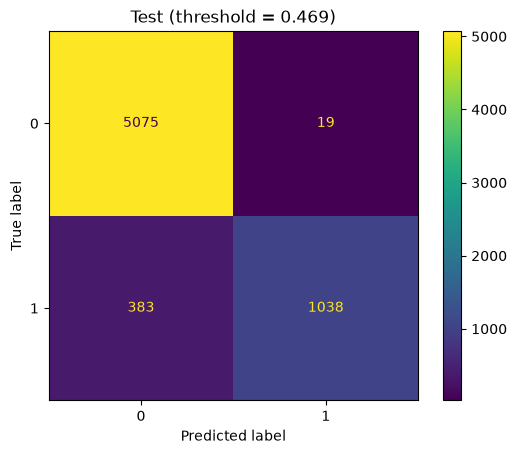


Training F1:                0.8547
Training balanced accuracy: 0.8756
Training ROC-AUC:           0.9692
Training average precision: 0.9365

Training classification report:
              precision    recall  f1-score   support

           0      0.936     0.997     0.965     20373
           1      0.986     0.754     0.855      5686

    accuracy                          0.944     26059
   macro avg      0.961     0.876     0.910     26059
weighted avg      0.947     0.944     0.941     26059



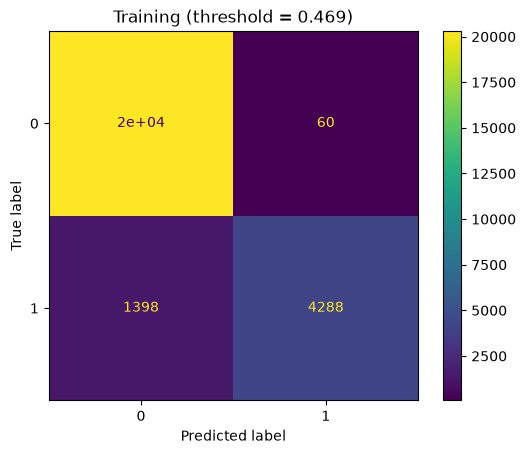

In [376]:
study = optuna_study(ntrials=120)
pipeline, threshold = retrain_and_evaluate(
    study, folds, preprocessor, X_train, y_train, X_test, y_test
)

In [377]:
# Bootstrap 95% confidence intervals for held-out test metrics
n_bootstrap = 2000
ci_rng = np.random.default_rng(42)

y_true = y_test.to_numpy()
y_prob = pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= threshold).astype(int)

point_estimates = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred, zero_division=0),
    "Recall": recall_score(y_true, y_pred, zero_division=0),
    "F1": f1_score(y_true, y_pred),
    "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, y_prob),
    "Average precision": average_precision_score(y_true, y_prob),
}

metric_values = {name: np.empty(n_bootstrap) for name in point_estimates}
n_test = len(y_true)
classes, counts = np.unique(y_true, return_counts=True)

for i in range(n_bootstrap):
    # Stratified bootstrap: preserve the class distribution in each resample
    sample_idx = np.concatenate([
        ci_rng.choice(np.flatnonzero(y_true == cls), size=count, replace=True)
        for cls, count in zip(classes, counts)
    ])

    y_boot = y_true[sample_idx]
    prob_boot = y_prob[sample_idx]
    pred_boot = y_pred[sample_idx]

    metric_values["Accuracy"][i] = accuracy_score(y_boot, pred_boot)
    metric_values["Balanced accuracy"][i] = balanced_accuracy_score(y_boot, pred_boot)
    metric_values["Precision"][i] = precision_score(y_boot, pred_boot, zero_division=0)
    metric_values["Recall"][i] = recall_score(y_boot, pred_boot, zero_division=0)
    metric_values["F1"][i] = f1_score(y_boot, pred_boot)
    metric_values["Precision (macro)"][i] = precision_score(y_boot, pred_boot, average="macro", zero_division=0)
    metric_values["F1 (macro)"][i] = f1_score(y_boot, pred_boot, average="macro", zero_division=0)
    metric_values["ROC-AUC"][i] = roc_auc_score(y_boot, prob_boot)
    metric_values["Average precision"][i] = average_precision_score(y_boot, prob_boot)

confidence_intervals = pd.DataFrame({
    "Metric": list(point_estimates),
    "Point estimate": list(point_estimates.values()),
    "95% CI lower": [
        np.percentile(metric_values[name], 2.5)
        for name in point_estimates
    ],
    "95% CI upper": [
        np.percentile(metric_values[name], 97.5)
        for name in point_estimates
    ],
})

confidence_intervals

,Metric,Point estimate,95% CI lower,95% CI upper
0,Accuracy,0.938296,0.933231,0.943668
1,Balanced accuracy,0.863371,0.852126,0.875278
2,Precision,0.982025,0.974407,0.989681
3,Recall,0.730471,0.707952,0.754398
4,F1,0.837772,0.822465,0.853503
5,Precision (macro),0.955926,0.951136,0.960987
6,F1 (macro),0.899838,0.890764,0.909366
7,ROC-AUC,0.946271,0.939218,0.953171
8,Average precision,0.901754,0.890975,0.912901


In [378]:
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['person_age_years','person_home_ownership','person_emp_length_years',..., 'high_lti_x_rent','log_person_income_usd','log_loan_amount_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [379]:
# params importance
optuna.importance.get_param_importances(study)

{'gamma': 0.22878131844801416,
 'eta': 0.22744830044720893,
 'colsample_bytree': 0.21317827804868336,
 'reg_lambda': 0.1262799019345344,
 'min_child_weight': 0.1098324950998203,
 'subsample': 0.068775085406976,
 'max_depth': 0.025704620614762815}

In [380]:
df = study.trials_dataframe()
top = df.sort_values("value", ascending=False).head(15)
print(top[["value", "params_max_depth", "params_min_child_weight", "params_gamma", "params_subsample", "params_colsample_bytree", "params_reg_lambda"]])
df.groupby("params_max_depth")["value"].agg(["max", "mean", "count"])

        value  params_max_depth  params_min_child_weight  params_gamma  \
99   0.845998                 7                 1.010424      2.003790   
117  0.845806                 7                 1.153177      2.112826   
61   0.845784                 7                 1.134278      2.049178   
77   0.845780                 7                 1.003608      2.236668   
116  0.845679                 7                 1.326430      2.004002   
106  0.845638                 7                 1.033121      2.077403   
110  0.845621                 7                 1.045165      2.437568   
112  0.845614                 7                 1.196066      2.002453   
54   0.845569                 7                 1.162179      2.019574   
107  0.845558                 7                 1.322607      2.301409   
104  0.845516                 7                 1.014928      2.239306   
103  0.845472                 7                 1.474951      2.291464   
63   0.845451                 7       

,max,mean,count
params_max_depth,,,
4,0.830970,0.814976,4
5,0.843326,0.840025,6
6,0.843989,0.838993,11
7,0.845998,0.844359,99


## <font color="orange">SHAP feature importance <font>

 98%|===================| 1178/1200 [00:56<00:01]        

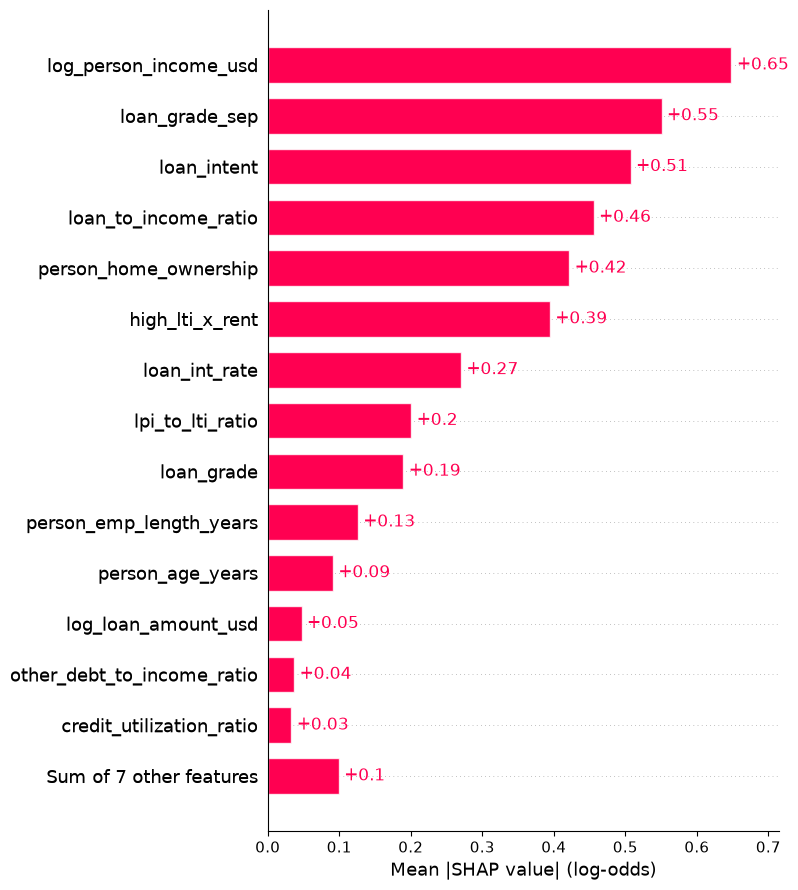

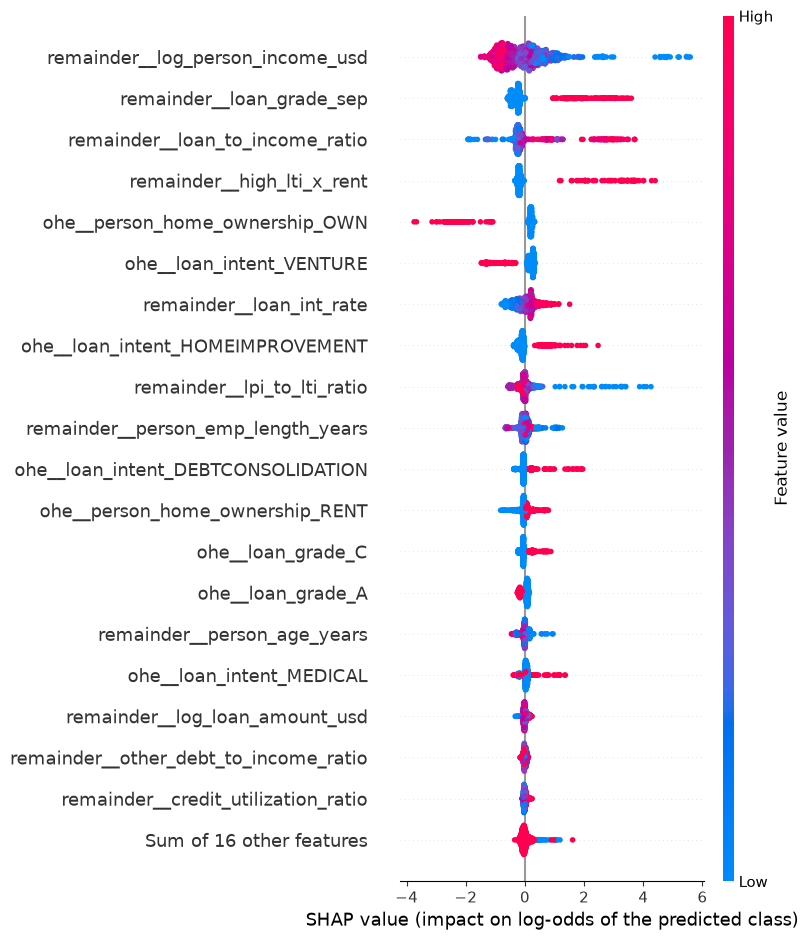

In [381]:
# Explain a manageable sample of the held-out data
background_raw = X_train # reference population
explain_raw = X_test # population to explain

# Background: 200-400 rows is enough for a tree explainer's reference distribution
rng = np.random.RandomState(42)
bg_idx = rng.choice(len(background_raw), size=min(400, len(background_raw)), replace=False)
explain_idx = rng.choice(len(explain_raw), size=min(1200, len(explain_raw)), replace=False)

# Extract necessary info from the best pipeline
preprocessor = pipeline.named_steps["preprocessor"]
best_clf = pipeline.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()

# preprocessing transform to get what enter the classifier
background = preprocessor.transform(background_raw.iloc[bg_idx])
explain_data = preprocessor.transform(explain_raw.iloc[explain_idx])

# Convert sparse matrices to dense if necessary
if hasattr(background, "toarray"):
    background = background.toarray()
if hasattr(explain_data, "toarray"):
    explain_data = explain_data.toarray()
# wrap to dataframes
background = pd.DataFrame(background, columns=feature_names, index=background_raw.index[bg_idx])
explain_data = pd.DataFrame(explain_data, columns=feature_names, index=explain_raw.index[explain_idx])

# calculate SHAP values. LinearExplainer for Logit
masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.TreeExplainer(best_clf, masker)
shap_values = explainer(explain_data)

# Map each encoded column back to its original feature
def to_original(fname, raw_cols): # raw_cols: original cols
    stripped = fname.split("__", 1)[-1]  # drop transformer prefix
    # a col belongs to an original feature c if name=c (like numetics) or starts with c_ (OHE) 
    matches = [c for c in raw_cols if stripped == c or stripped.startswith(c + "_")]
    return max(matches, key=len) if matches else stripped  # longest match avoids prefix clashes

groups = np.array([to_original(f, X_train.columns) for f in feature_names])

# Sum SHAP values within each original feature per sample, then take the mean absolute value.
# SHAP is additive, so summing signed values per sample is the correct way to aggregate.
agg_df = (
    pd.DataFrame(shap_values.values, columns=feature_names)
    .T.groupby(groups).sum().T
)
agg_exp = shap.Explanation(
    values=agg_df.values,
    base_values=shap_values.base_values,
    feature_names=list(agg_df.columns),
)

# Importance per ORIGINAL feature (one-hot levels combined)
shap.plots.bar(agg_exp, max_display=15, show=False)
plt.xlabel("Mean |SHAP value| (log-odds)")
plt.tight_layout()
plt.show()

# Direction of impact per ENCODED feature (colors need the encoded values)
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.xlabel("SHAP value (impact on log-odds of the predicted class)")
plt.tight_layout()
plt.show()
